In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"]='4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import sys
import cv2
import torch
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm import tqdm
import traceback

In [72]:
# h5파일 key 확인
def explore_h5(f, prefix=''):
    for key in f.keys():
        obj = f[key]
        fullname = prefix + '/' + key
        print(f'{fullname}')
        if isinstance(obj, h5py.Dataset):
            print(f'  type  : Dataset')
            print(f'  shape : {obj.shape}')
            print(f'  dtype : {obj.dtype}')
            #print(f'  max : {np.max(obj)} , min : {np.min(obj)}')
        else:
            print(f'  type  : Group')
        if obj.attrs:
            for k, v in obj.attrs.items():
                print(f'  attr  : {k} = {v}')
        if isinstance(obj, h5py.Group):
            explore_h5(obj, fullname)

h5_dir =  '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/mrNIRP_driv_dl_datax'
files = sorted([f for f in os.listdir(h5_dir) if f.endswith('.h5')])

for subject in files:
    print('='*80)
    print(subject)
    with h5py.File(os.path.join(h5_dir, subject), 'r') as f:
        explore_h5(f)

subject10_driving_still_940_uv_windowed.h5
/gt_ppg
  type  : Dataset
  shape : (14, 300)
  dtype : float64
/video
  type  : Dataset
  shape : (14, 300, 64, 64)
  dtype : float32
subject10_garage_still_940_uv_windowed.h5
/gt_ppg
  type  : Dataset
  shape : (8, 300)
  dtype : float64
/video
  type  : Dataset
  shape : (8, 300, 64, 64)
  dtype : float32
subject11_driving_still_940_uv_windowed.h5
/gt_ppg
  type  : Dataset
  shape : (16, 300)
  dtype : float64
/video
  type  : Dataset
  shape : (16, 300, 64, 64)
  dtype : float32
subject11_garage_still_940_uv_windowed.h5
/gt_ppg
  type  : Dataset
  shape : (9, 300)
  dtype : float64
/video
  type  : Dataset
  shape : (9, 300, 64, 64)
  dtype : float32
subject12_driving_still_940_uv_windowed.h5
/gt_ppg
  type  : Dataset
  shape : (15, 300)
  dtype : float64
/video
  type  : Dataset
  shape : (15, 300, 64, 64)
  dtype : float32
subject12_garage_still_940_uv_windowed.h5
/gt_ppg
  type  : Dataset
  shape : (9, 300)
  dtype : float64
/video
  ty

Subject1_motion_940_uv_windowed  mean=-0.000  std=0.163  min=-3.000  max=3.000
Subject1_still_940_uv_windowed  mean=-0.000  std=0.151  min=-3.000  max=3.000
Subject2_motion_940_uv_windowed  mean=-0.000  std=0.164  min=-3.000  max=3.000
Subject2_still_940_uv_windowed  mean=-0.000  std=0.411  min=-3.000  max=3.000
Subject3_motion_940_uv_windowed  mean=-0.000  std=0.190  min=-3.000  max=3.000
Subject3_still_940_uv_windowed  mean=-0.000  std=0.178  min=-3.000  max=3.000
Subject4_motion_940_uv_windowed  mean=-0.000  std=0.166  min=-3.000  max=3.000
Subject4_still_940_uv_windowed  mean=-0.000  std=0.149  min=-3.000  max=3.000
Subject5_still_940_uv_windowed  mean=0.000  std=0.149  min=-3.000  max=3.000
Subject6_motion_940_uv_windowed  mean=-0.000  std=0.164  min=-3.000  max=3.000
Subject6_still_940_uv_windowed  mean=-0.000  std=0.157  min=-3.000  max=3.000
Subject7_motion_940_uv_windowed  mean=-0.000  std=0.176  min=-3.000  max=3.000
Subject7_still_940_uv_windowed  mean=-0.000  std=0.152  min

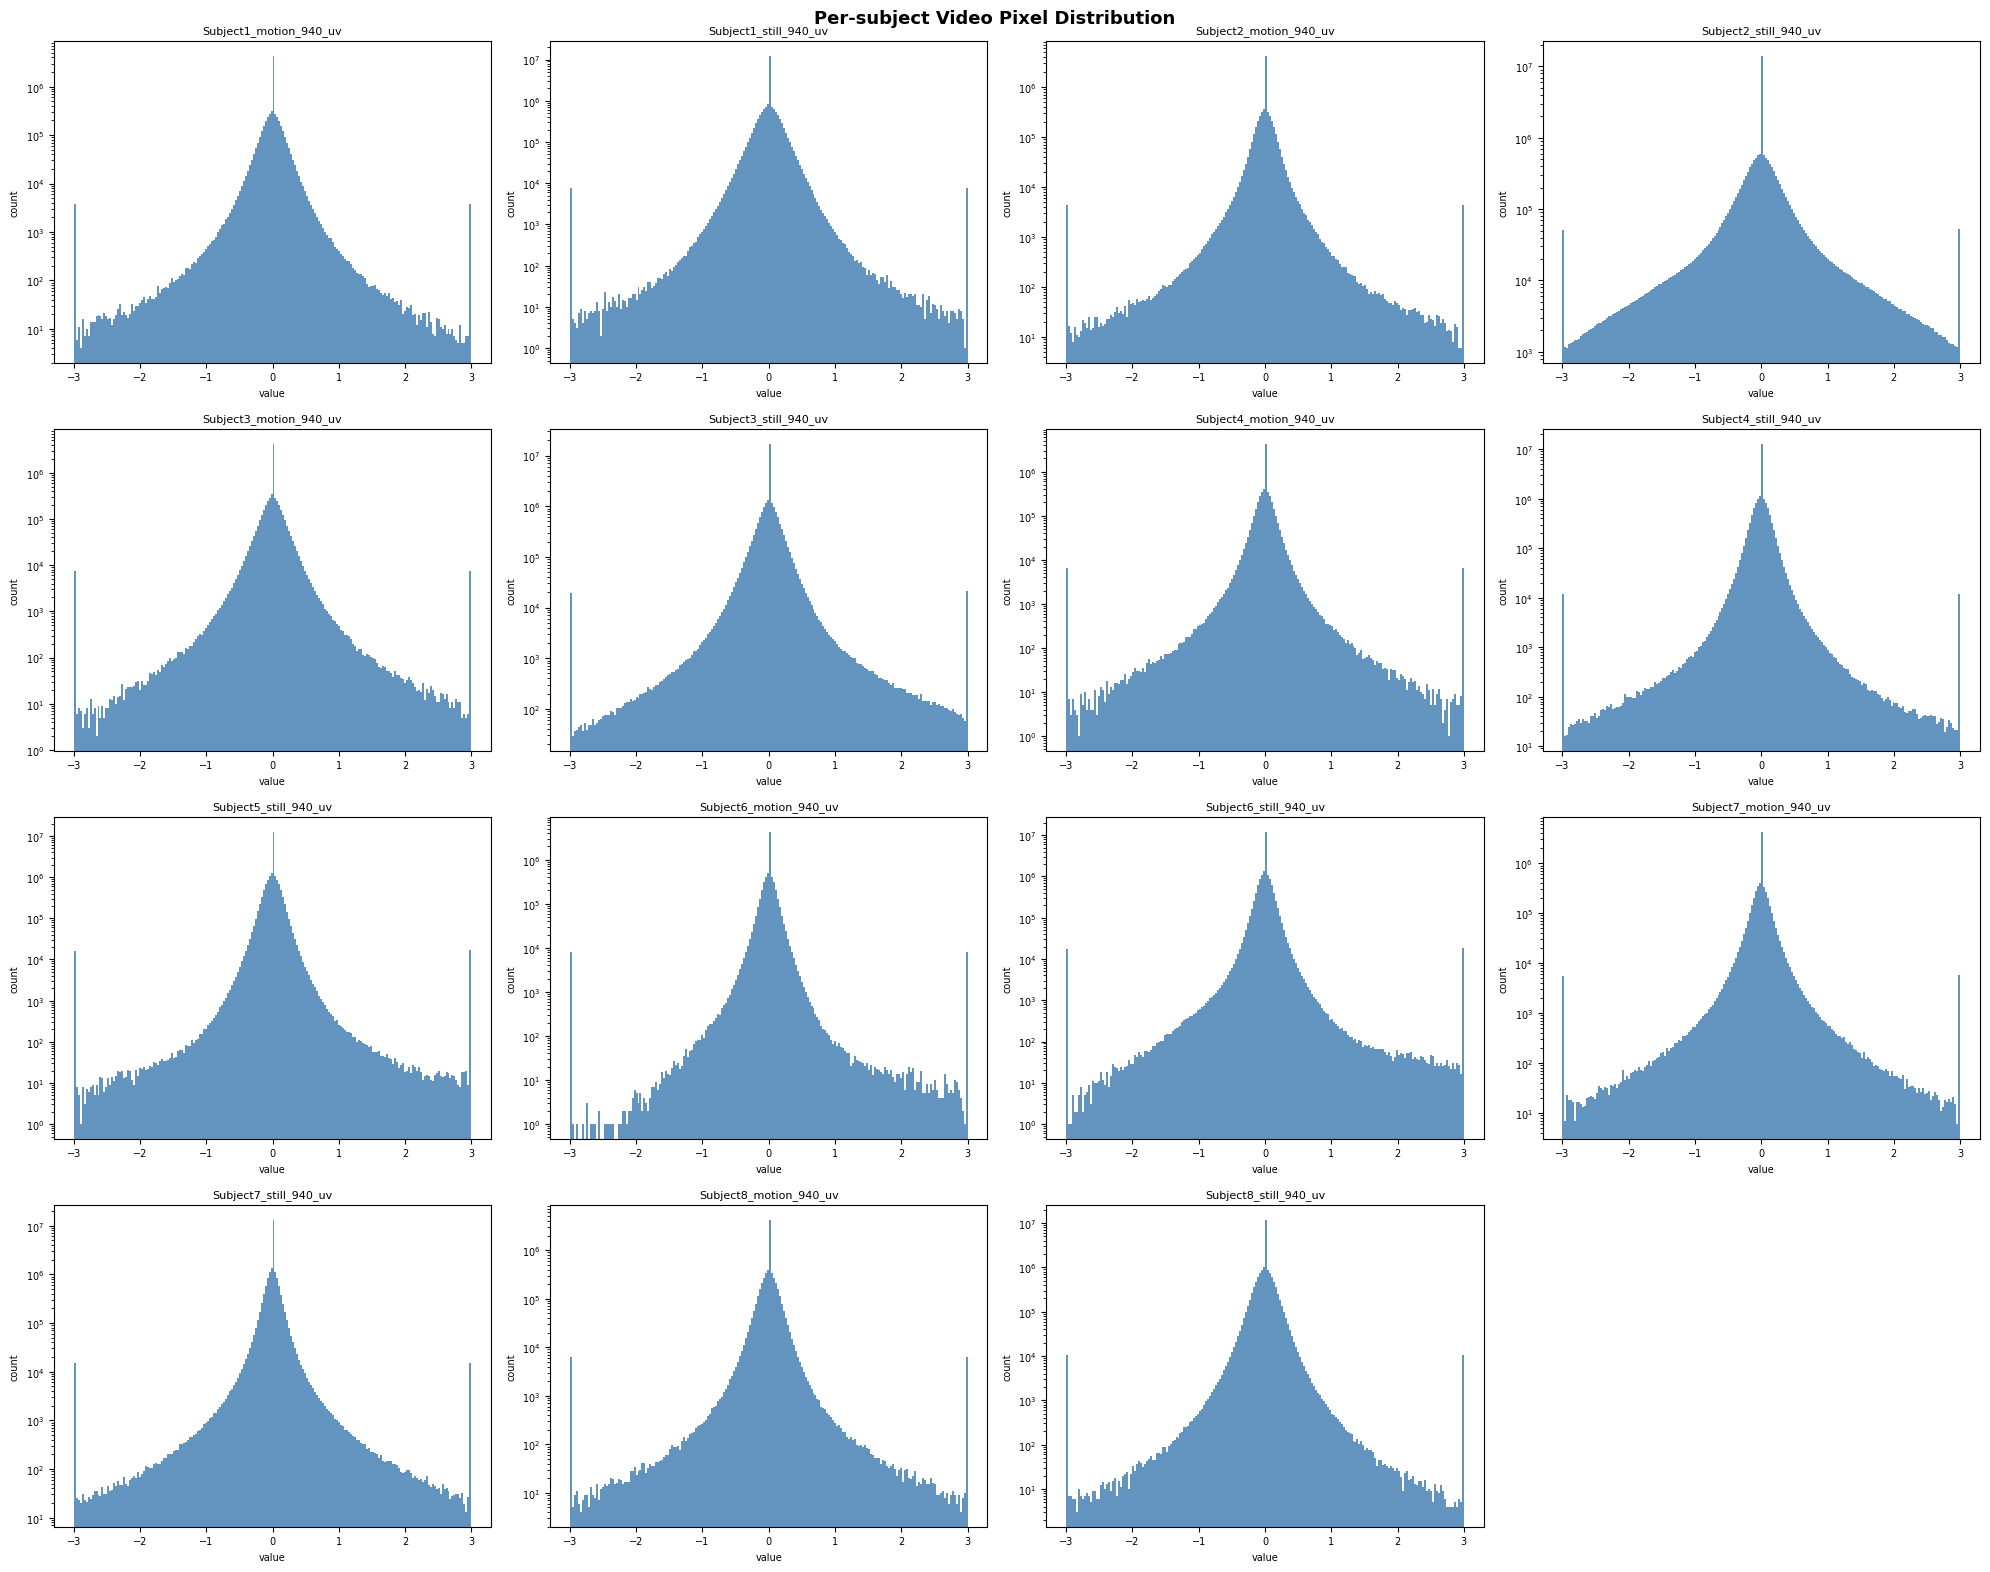

In [46]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

H5_DIR   = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/mrNIRP_dl_datax'
SAVE_DIR = os.path.join(H5_DIR, 'histogram_plots')
os.makedirs(SAVE_DIR, exist_ok=True)

h5_files = sorted(Path(H5_DIR).glob('*.h5'))
n = len(h5_files)
ncols = 4
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = axes.ravel()

for i, h5_path in enumerate(h5_files):
    with h5py.File(str(h5_path), 'r') as f:
        flat = f['video'][:].ravel().astype(np.float32)

    axes[i].hist(flat, bins=200, color='steelblue', alpha=0.85, log = True)
    #axes[i].axvline( 3.0, color='red',    lw=1.2, ls='--')
    #axes[i].axvline(-3.0, color='orange', lw=1.2, ls='--')
    axes[i].set_title(h5_path.stem.replace('_windowed', ''), fontsize=8)
    axes[i].set_xlabel('value', fontsize=7)
    axes[i].set_ylabel('count', fontsize=7)
    axes[i].tick_params(labelsize=7)
    print(f"{h5_path.stem}  mean={flat.mean():.3f}  std={flat.std():.3f}  min={flat.min():.3f}  max={flat.max():.3f}")

# 남은 axes 숨기기
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Per-subject Video Pixel Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
save_path = os.path.join(SAVE_DIR, 'per_subject_histogram.png')
#plt.savefig(save_path, dpi=150, bbox_inches='tight')
print(f'\n저장: {save_path}')

Subject1_motion_940_uv  mean=0.1474  std=0.1756  min=0.0000  max=0.7077
Subject1_still_940_uv  mean=0.1425  std=0.1704  min=0.0000  max=0.6742
Subject2_motion_940_uv  mean=0.1655  std=0.1876  min=0.0000  max=0.6673
Subject2_still_940_uv  mean=0.1222  std=0.1495  min=0.0000  max=0.8228
Subject3_motion_940_uv  mean=0.1157  std=0.1343  min=0.0000  max=0.5147
Subject3_still_940_uv  mean=0.1439  std=0.1723  min=0.0000  max=0.6986
Subject4_motion_940_uv  mean=0.1904  std=0.2138  min=0.0000  max=0.7751
Subject4_still_940_uv  mean=0.1973  std=0.2227  min=0.0000  max=0.7773
Subject5_still_940_uv  mean=0.1730  std=0.1859  min=0.0000  max=0.6293
Subject6_motion_940_uv  mean=0.1820  std=0.1946  min=0.0000  max=0.5983
Subject6_still_940_uv  mean=0.1838  std=0.1971  min=0.0000  max=0.6129
Subject7_motion_940_uv  mean=0.2152  std=0.2424  min=0.0000  max=0.8118
Subject7_still_940_uv  mean=0.2236  std=0.2549  min=0.0000  max=0.8457
Subject8_motion_940_uv  mean=0.1635  std=0.1821  min=0.0000  max=0.9139

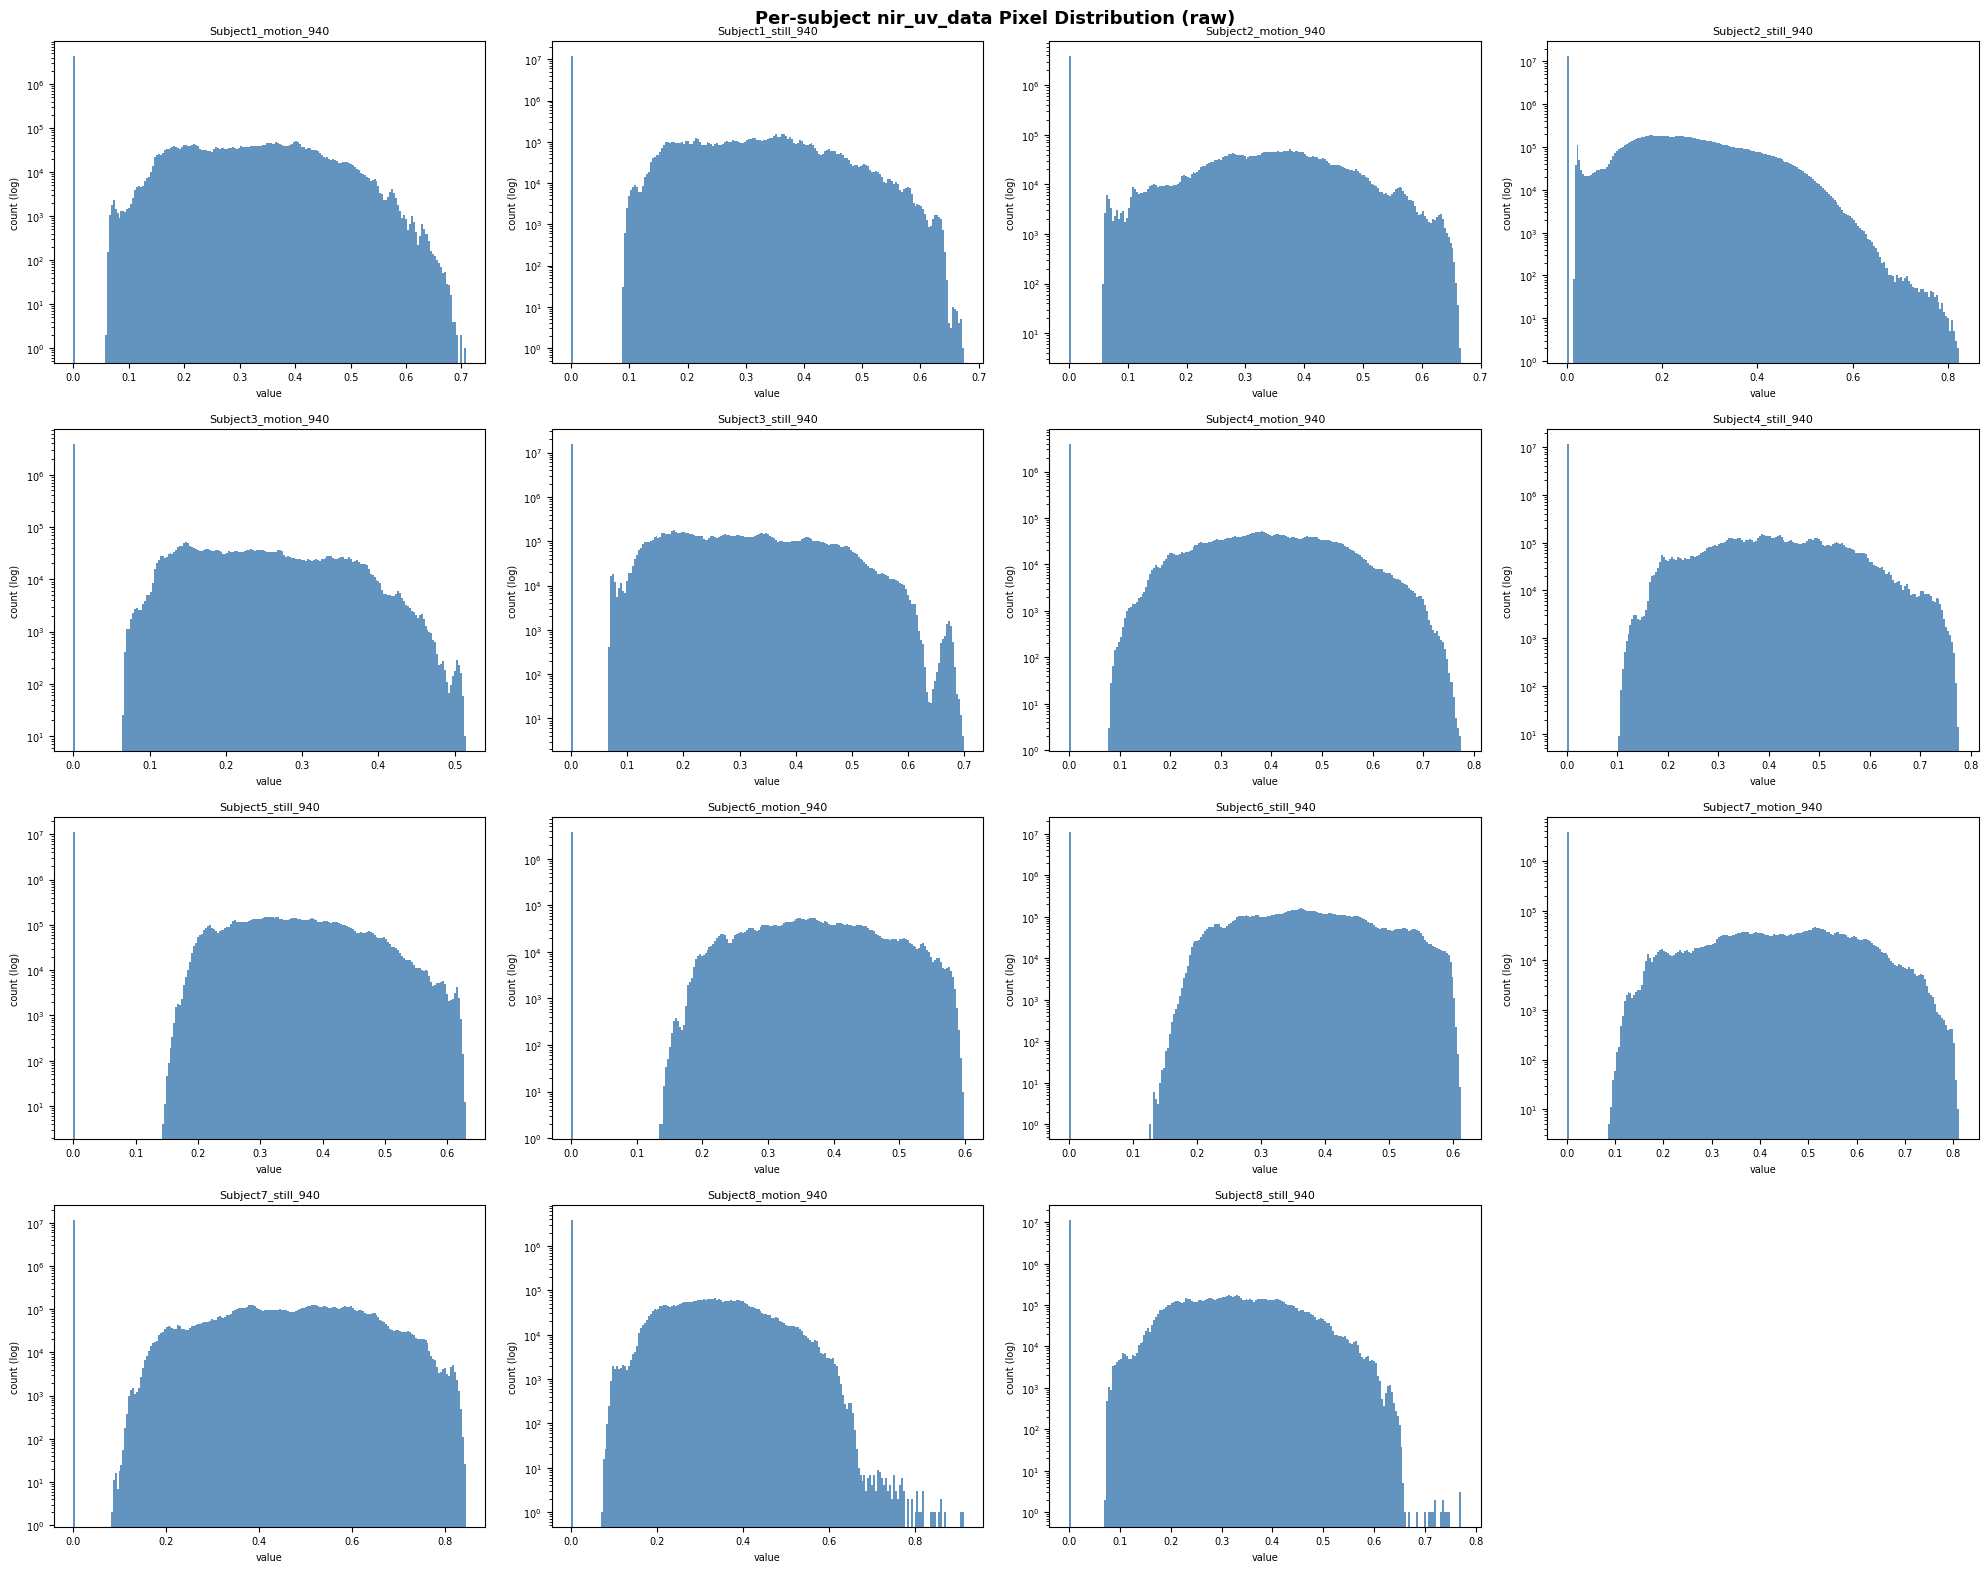

In [48]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

H5_DIR   = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/MR-nirp_indoor_registration_70'
SAVE_DIR = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/histogram_plots_raw'
os.makedirs(SAVE_DIR, exist_ok=True)

h5_files = sorted(Path(H5_DIR).glob('*.h5'))
n = len(h5_files)
ncols = 4
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = axes.ravel()

for i, h5_path in enumerate(h5_files):
    with h5py.File(str(h5_path), 'r') as f:
        flat = f['nir_uv_data'][:].ravel().astype(np.float32)

    axes[i].hist(flat, bins=200, color='steelblue', alpha=0.85, log=True)
    axes[i].set_title(h5_path.stem.replace('_uv', ''), fontsize=8)
    axes[i].set_xlabel('value', fontsize=7)
    axes[i].set_ylabel('count (log)', fontsize=7)
    axes[i].tick_params(labelsize=7)
    print(f"{h5_path.stem}  mean={flat.mean():.4f}  std={flat.std():.4f}  min={flat.min():.4f}  max={flat.max():.4f}")

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Per-subject nir_uv_data Pixel Distribution (raw)', fontsize=13, fontweight='bold')
plt.tight_layout()
save_path = os.path.join(SAVE_DIR, 'per_subject_histogram_raw.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
print(f'\n저장: {save_path}')

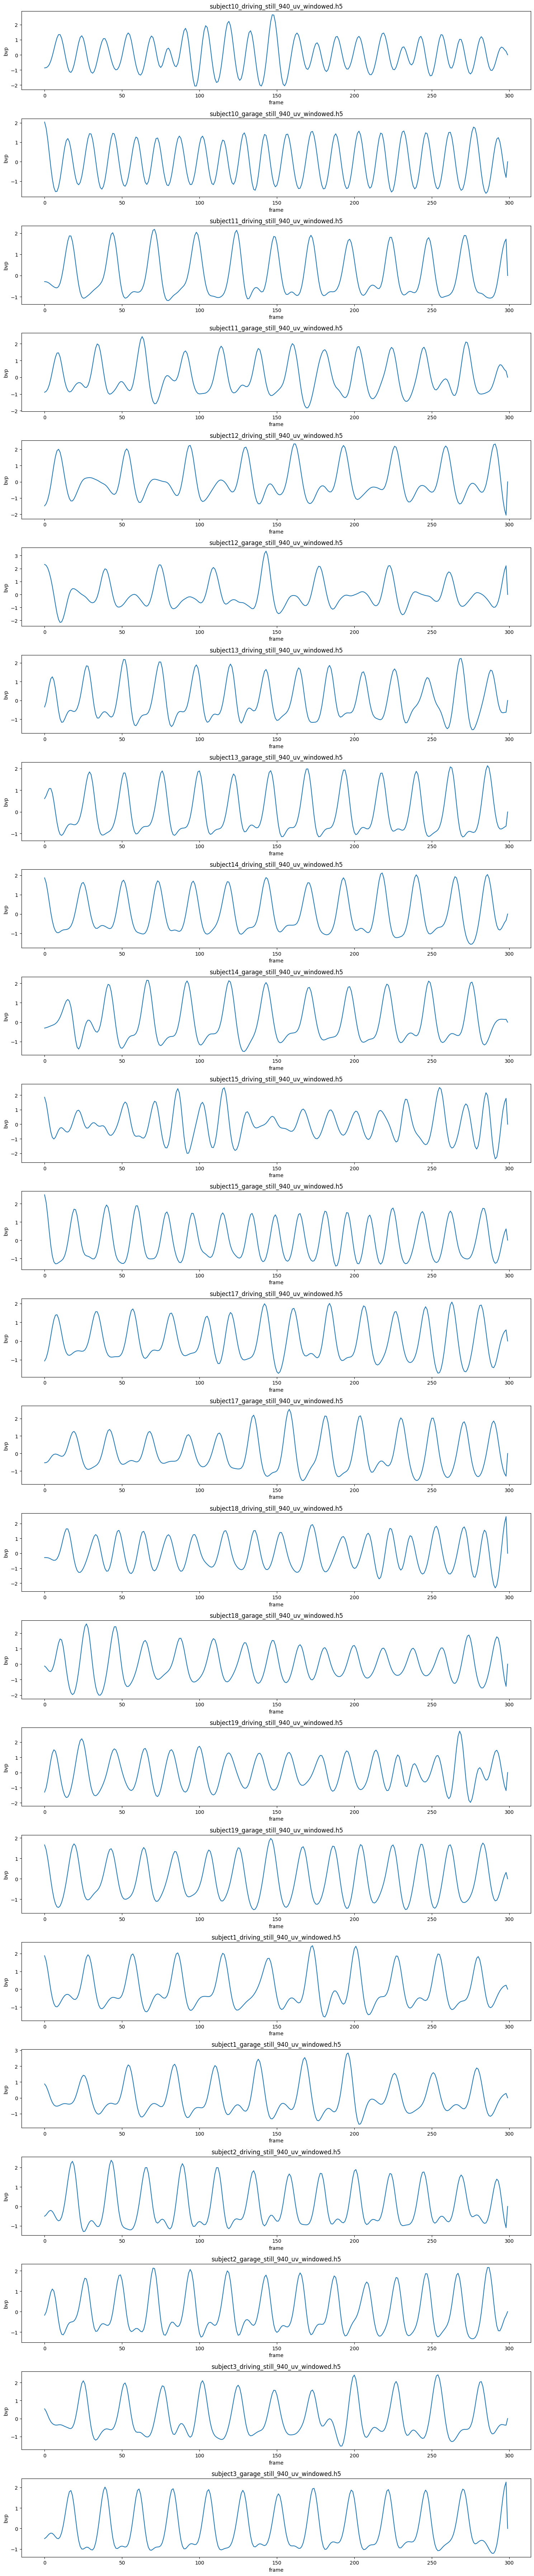

저장완료: bvp_all_subjects.png


In [71]:
# gt ppg 파형확인
import h5py
import os
import matplotlib.pyplot as plt

h5_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/mrNIRP_driv_dl_datax'
files = sorted([f for f in os.listdir(h5_dir) if f.endswith('.h5')])

fig, axes = plt.subplots(len(files), 1, figsize=(15, 3*len(files)))

for i, subject in enumerate(files):
    with h5py.File(os.path.join(h5_dir, subject), 'r') as f:
        bvp = f['gt_ppg'][0][:]
    
    axes[i].plot(bvp)
    axes[i].set_title(subject)
    #axes[i].set_xlim(0, 2000)
    axes[i].set_xlabel('frame')
    axes[i].set_ylabel('bvp')

plt.tight_layout()
plt.show()
print("저장완료: bvp_all_subjects.png")

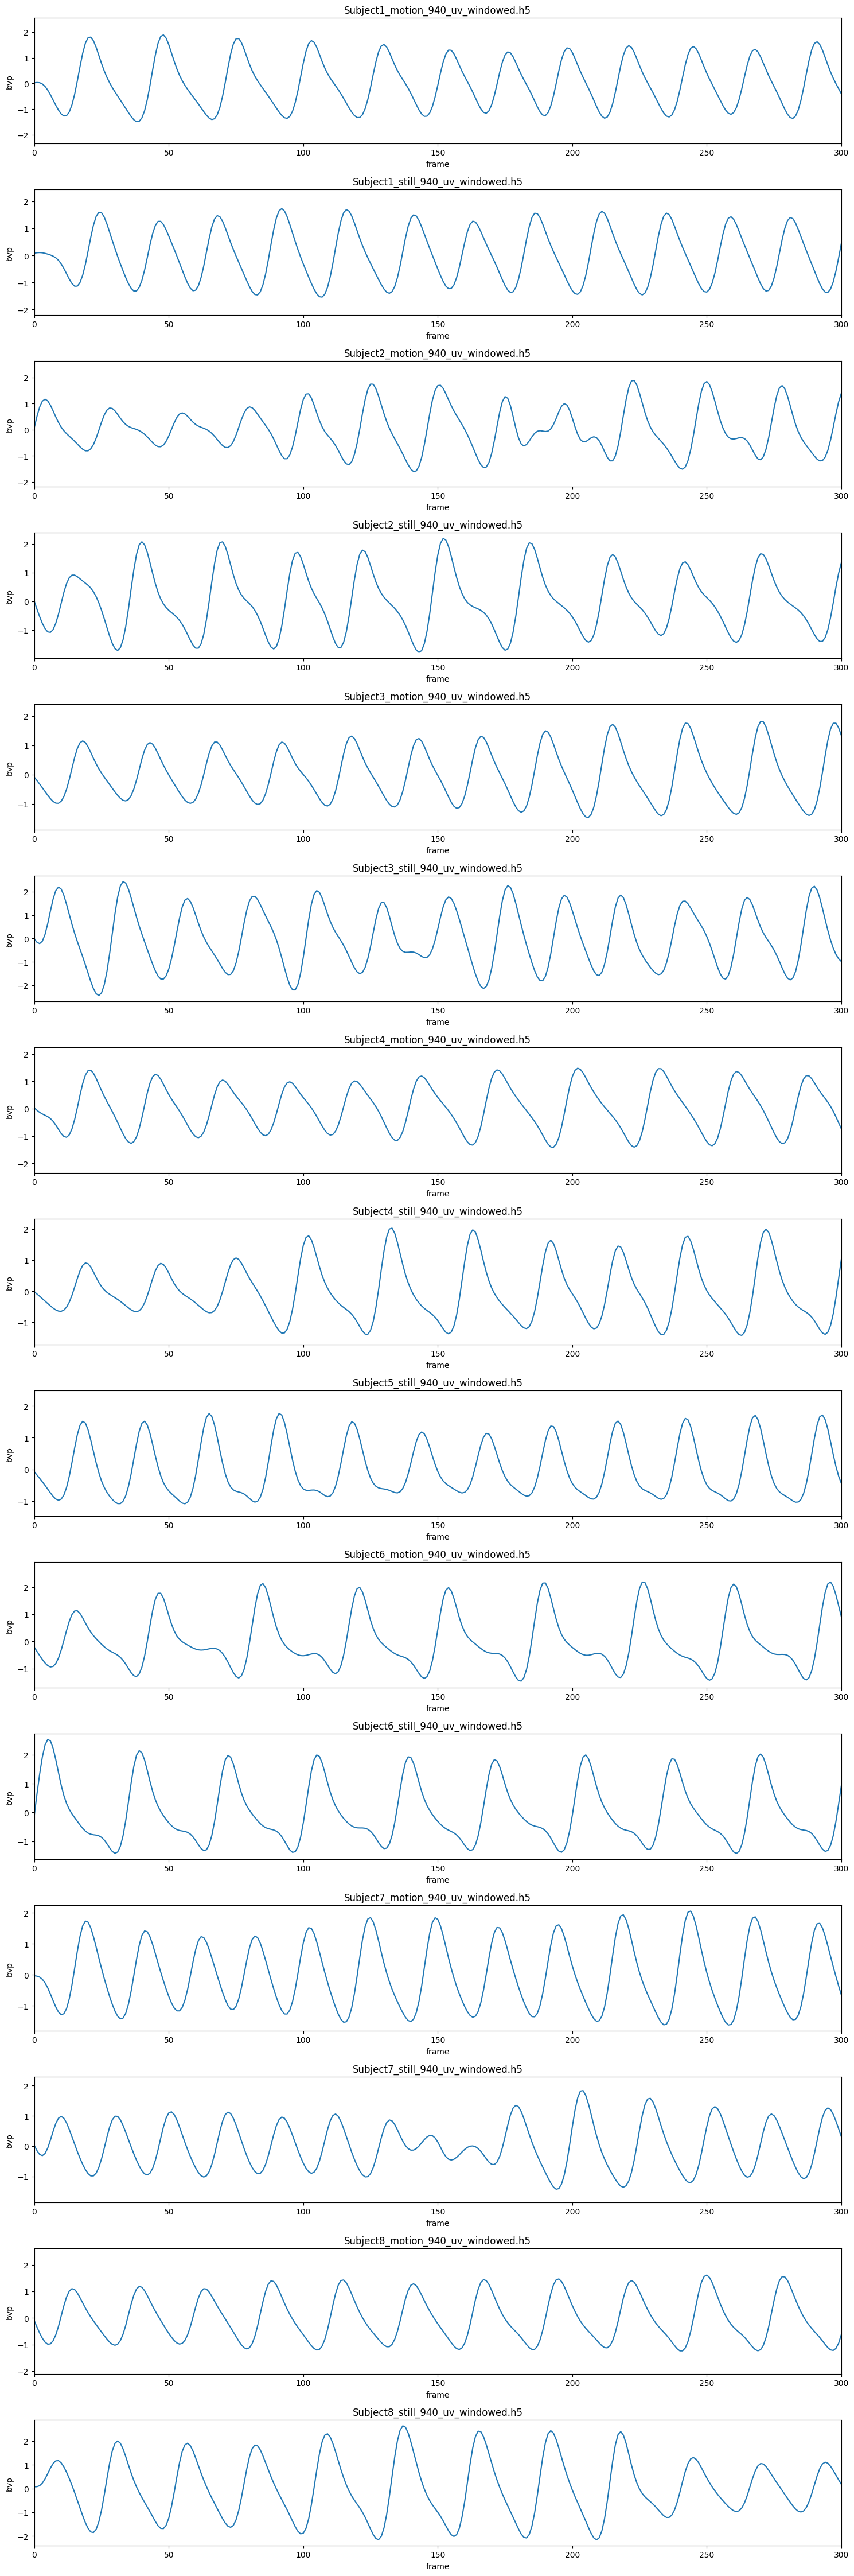

저장완료: bvp_all_subjects.png


In [82]:
# gt ppg 파형확인
import h5py
import os
import matplotlib.pyplot as plt

h5_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/MR-nirp_indoor_dl_data_900frame'
files = sorted([f for f in os.listdir(h5_dir) if f.endswith('.h5')])

fig, axes = plt.subplots(len(files), 1, figsize=(15, 3*len(files)))

for i, subject in enumerate(files):
    with h5py.File(os.path.join(h5_dir, subject), 'r') as f:
        bvp = f['gt_ppg'][:][0]
    
    axes[i].plot(bvp)
    axes[i].set_title(subject)
    axes[i].set_xlim(0, 300)
    axes[i].set_xlabel('frame')
    axes[i].set_ylabel('bvp')

plt.tight_layout()
plt.show()
print("저장완료: bvp_all_subjects.png")

Subject1_motion_940_uv_windowed.h5
(2, 900, 64, 64)
float32


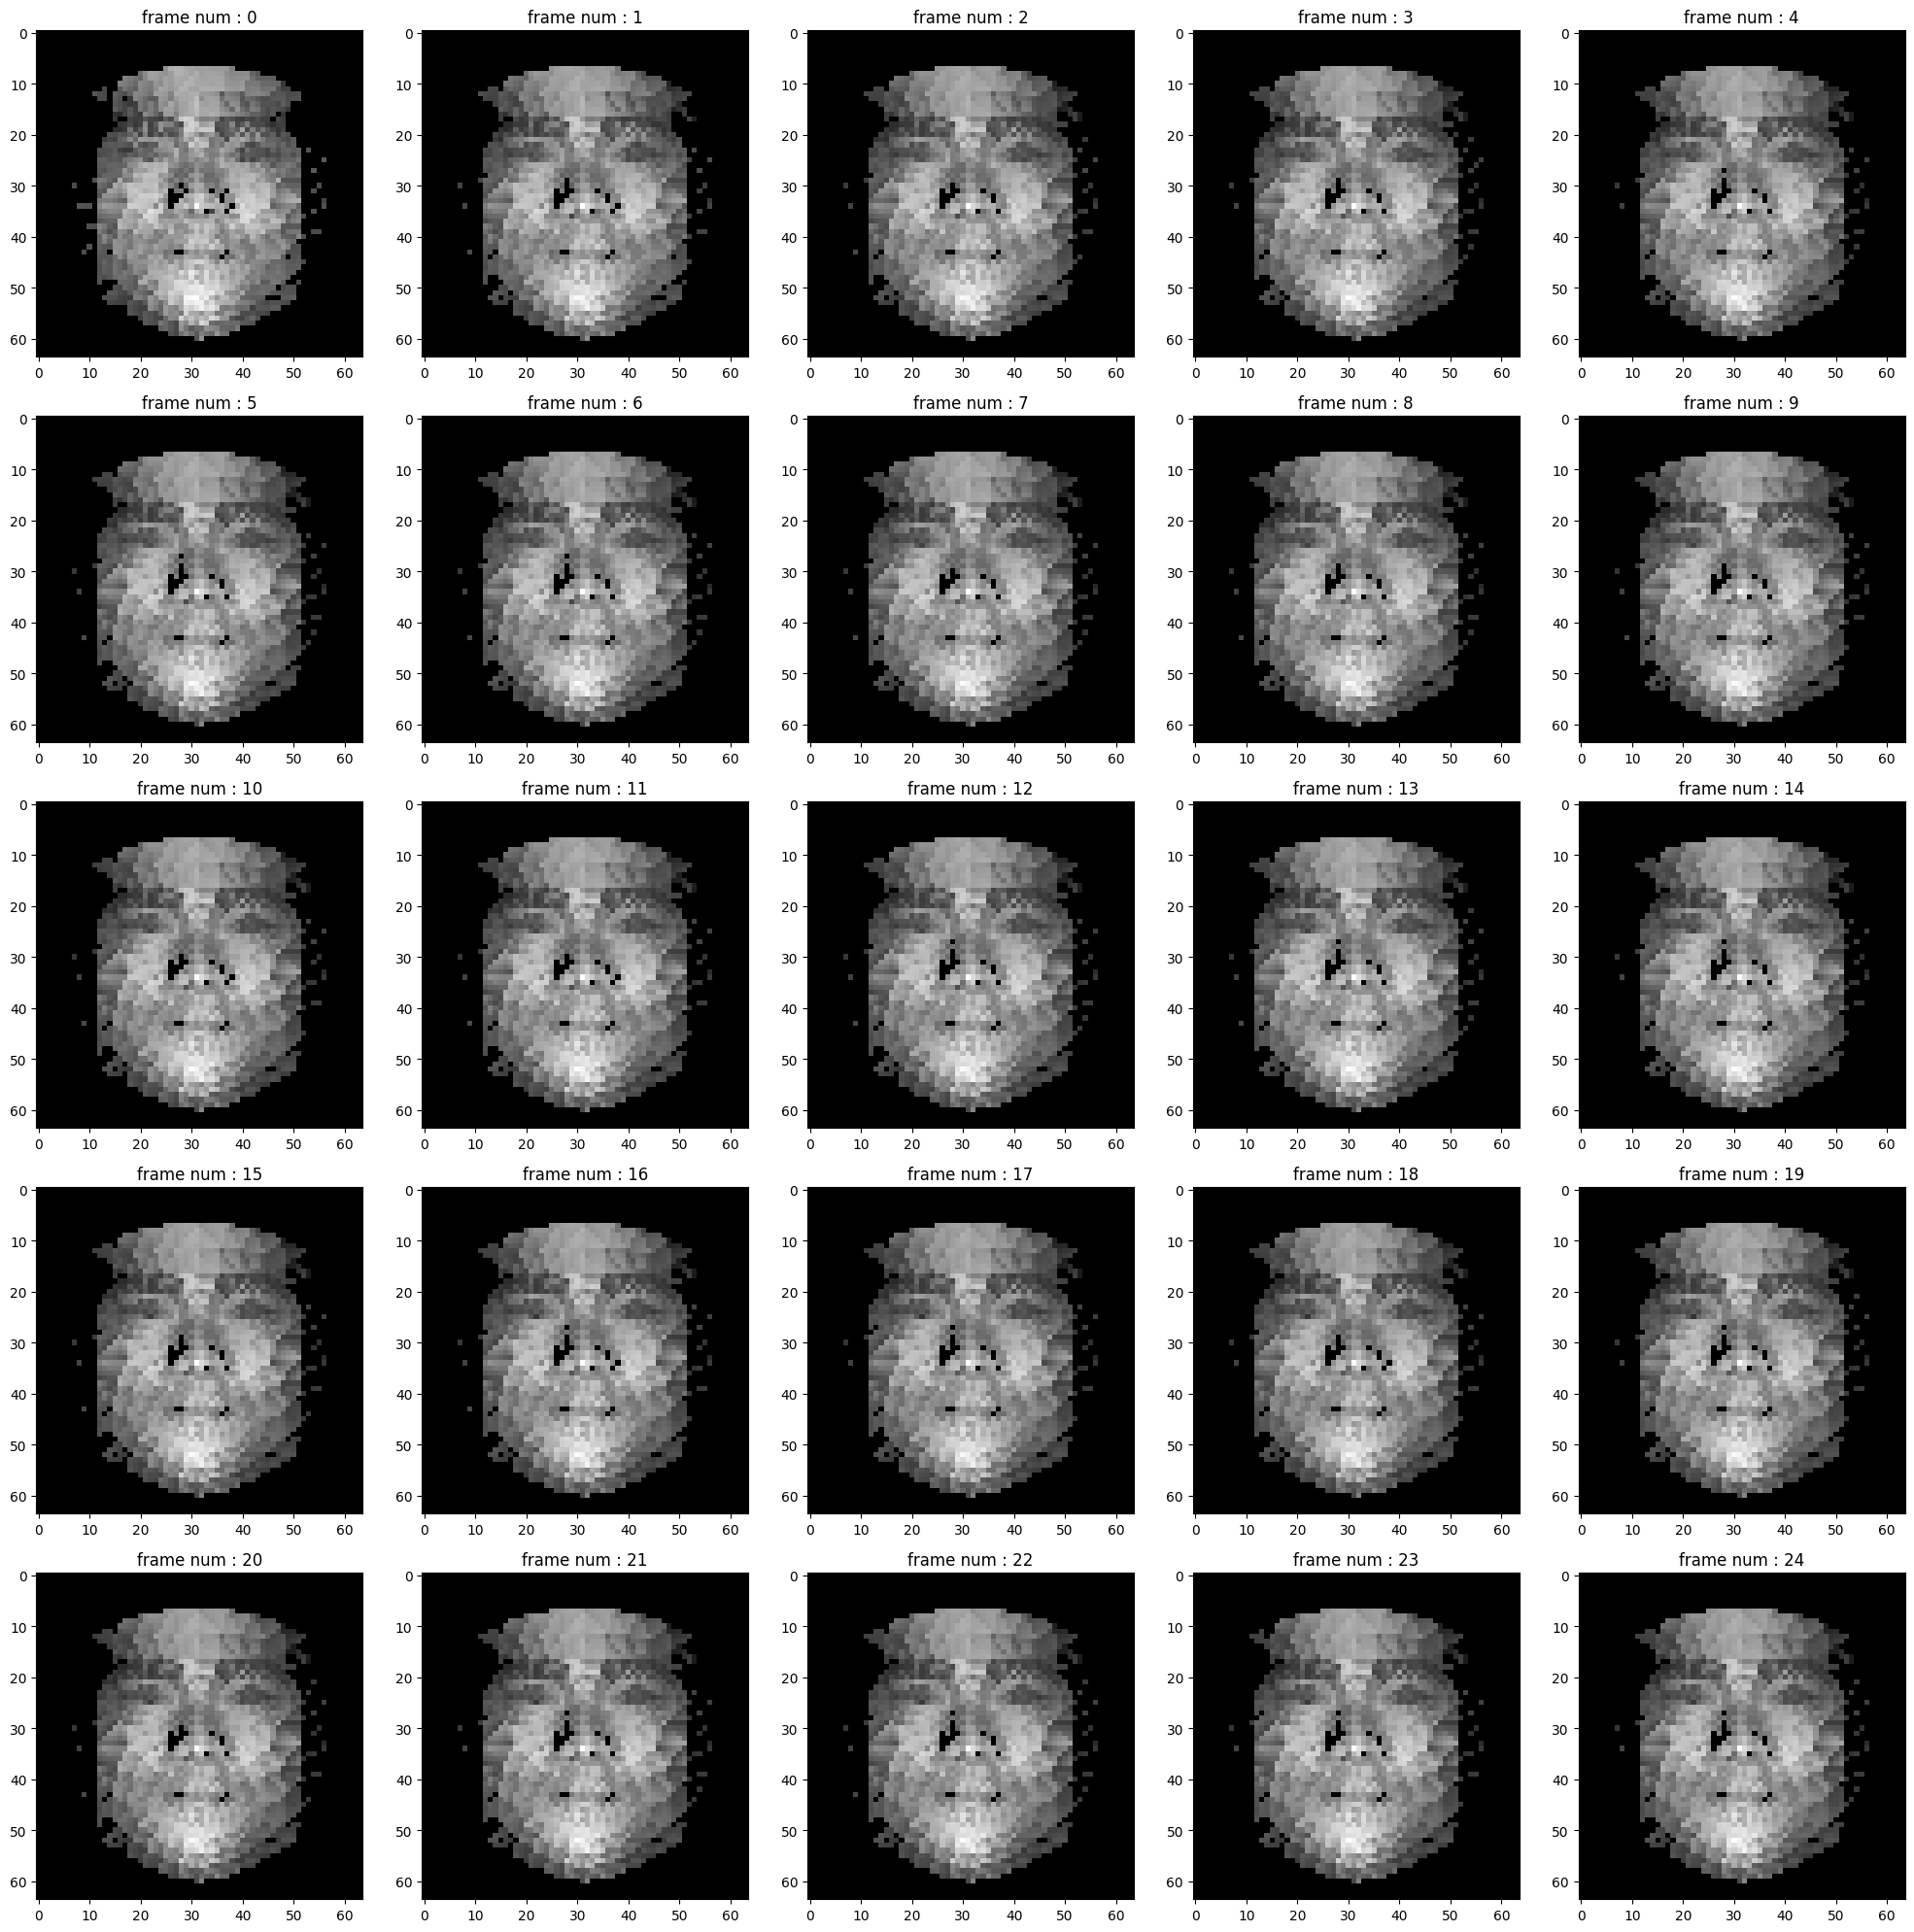

In [78]:
#원본영상확인
id = 0

h5_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/MR-nirp_indoor_dl_data_900frame'
files = sorted([f for f in os.listdir(h5_dir) if f.endswith('.h5')])
print(files[id])

with h5py.File(os.path.join(h5_dir, files[id]), 'r') as f:
    video = f['video'][:]

print(video.shape)
print(video.dtype)
#비디오 사진 확인
fig, axes = plt.subplots(5,5, figsize = (20,20))
axes = axes.flatten()
for i, im in enumerate(video[0][:25]) :
    #im = im.squeeze(-1)
    axes[i].imshow(im, cmap ='gray')
    axes[i].set_title(f'frame num : {i}')

plt.tight_layout()
plt.show()

13_uv.h5
(1287, 64, 64)
float32


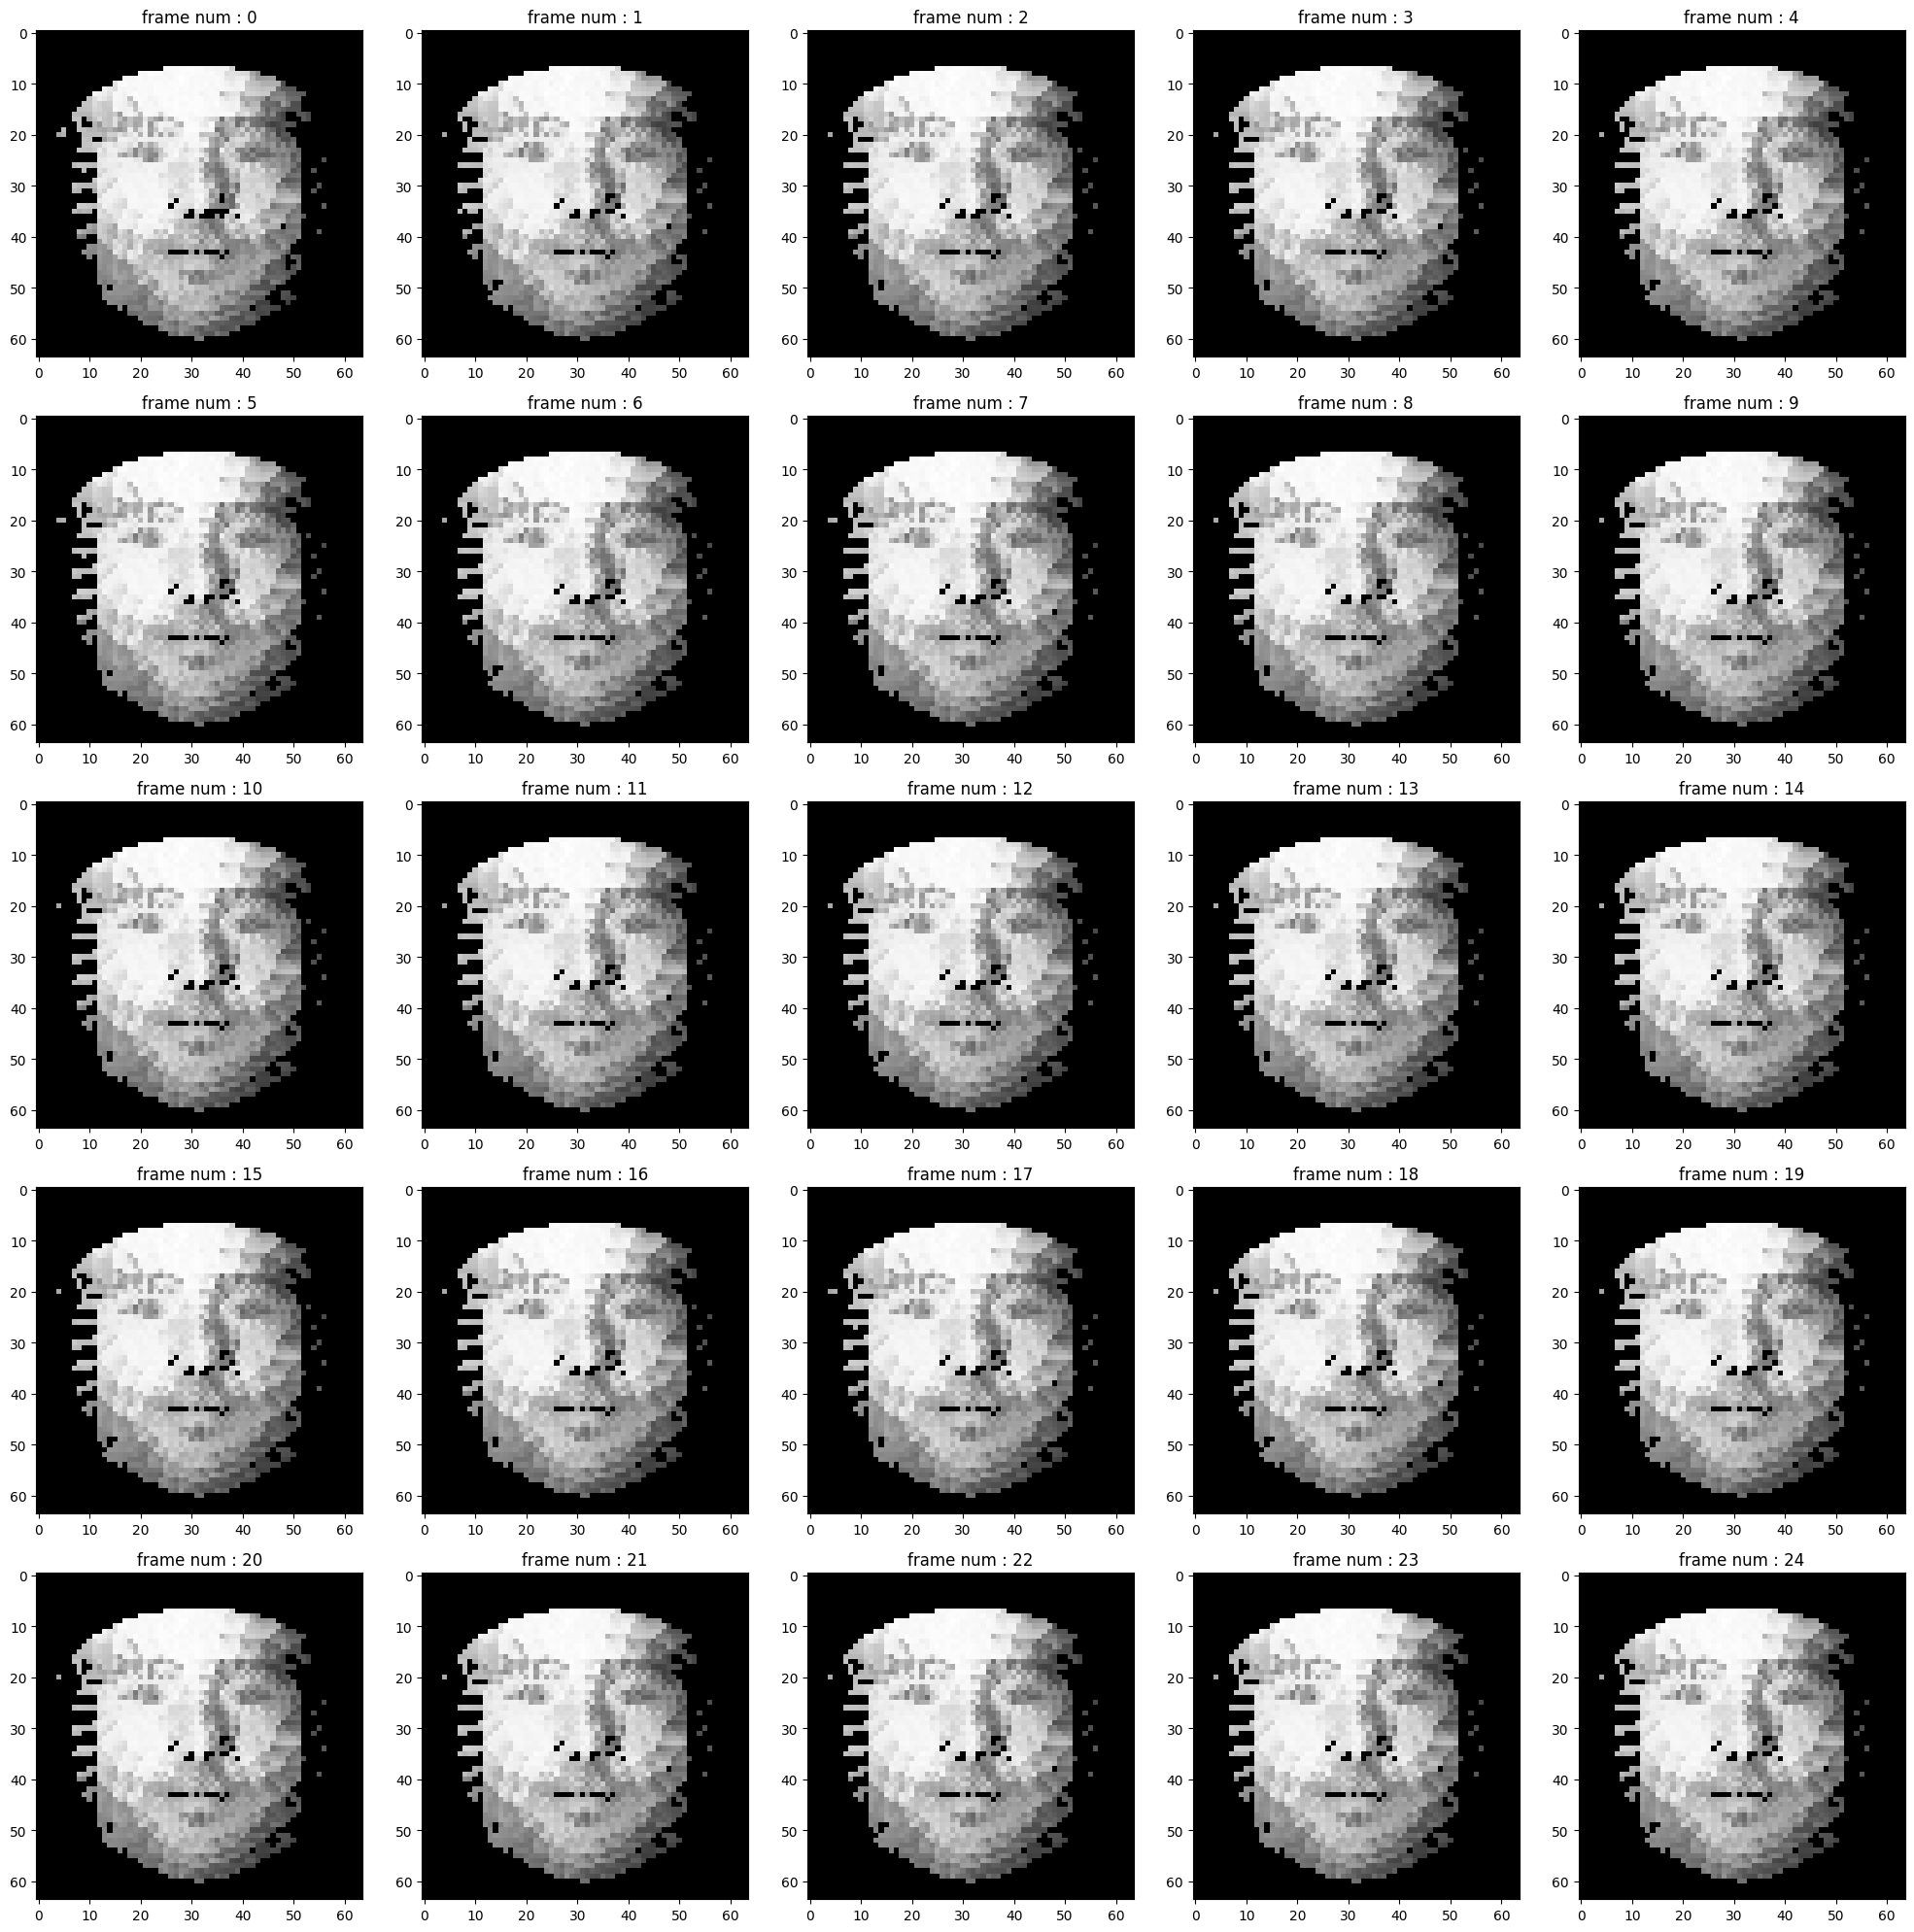

In [19]:
#registration 결과 확인
regist_dir ='/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/IMVIA-NIR_registration'
people = sorted(os.listdir(regist_dir))

id = 3
print(people[id])
with h5py.File(os.path.join(regist_dir, people[id]), 'r') as f:
    video = f['nir_uv_data'][:]

print(video.shape)
print(video.dtype)


fig, axes = plt.subplots(5,5, figsize = (20,20))
axes = axes.flatten()
for i, im in enumerate(video[:25]) :

    axes[i].imshow(im, cmap ='gray')
    axes[i].set_title(f'frame num : {i}')

plt.tight_layout()
plt.show()

13_uv_windowed.h5
(4, 300, 64, 64)
float32
0.9194128
0.0


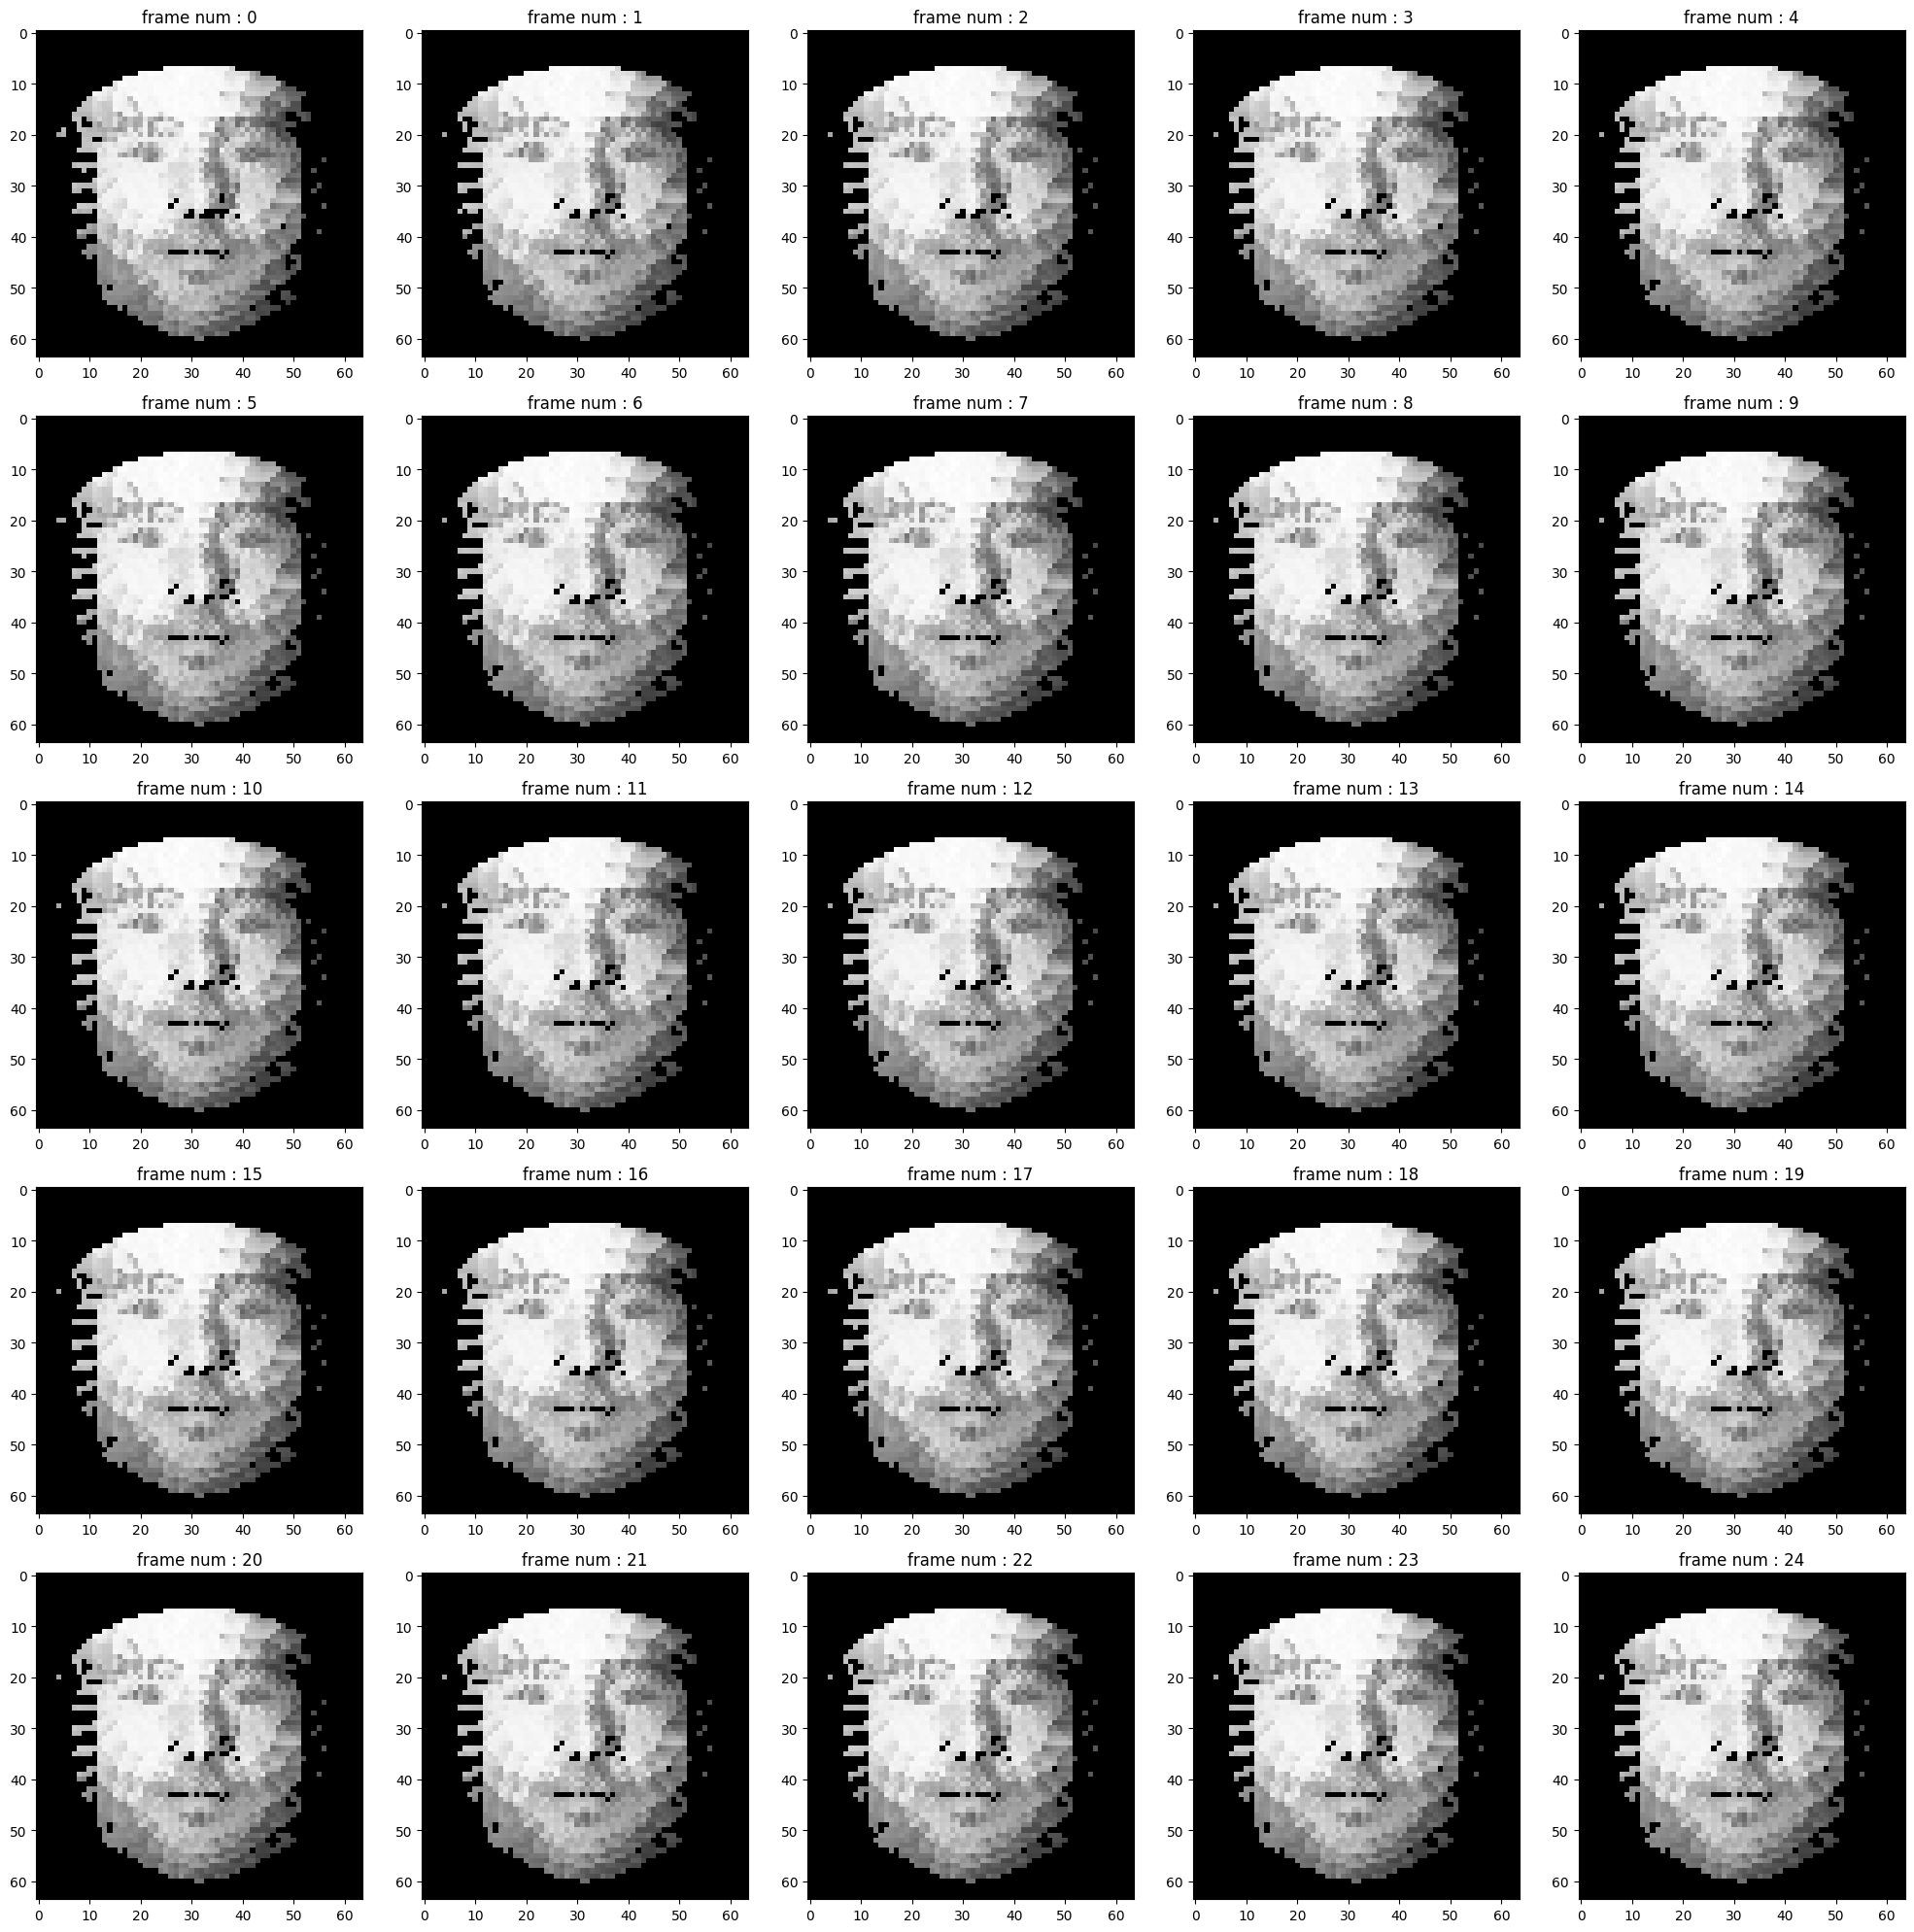

In [12]:
#dl_data 확인
regist_dir ='/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/IMVIA-NIR_dl_data'
people = sorted(os.listdir(regist_dir))

id = 3
print(people[id])
with h5py.File(os.path.join(regist_dir, people[id]), 'r') as f:
    video = f['video'][:]

print(video.shape)
print(video.dtype)
print(np.max(video))
print(np.min(video))


fig, axes = plt.subplots(5,5, figsize = (20,20))
axes = axes.flatten()
for i, im in enumerate(video[0][:25]) :

    axes[i].imshow(im, cmap ='gray')
    axes[i].set_title(f'frame num : {i}')

plt.tight_layout()
plt.show()

In [19]:
#dl_data 확인
regist_dir ='/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/raw_video'
people = sorted(os.listdir(regist_dir))

id = 3
print(people[id])
with h5py.File(os.path.join(regist_dir, people[id]), 'r') as f:
    video = f['video'][:]

print(video.shape)
print(video.dtype)
print(np.max(video))
print(np.min(video))


fig, axes = plt.subplots(5,5, figsize = (20,20))
axes = axes.flatten()
for i, im in enumerate(video[:25]) :

    axes[i].imshow(im, cmap ='gray')
    axes[i].set_title(f'frame num : {i}')

plt.tight_layout()
plt.show()

raw_video_[A004_20250610].h5
(123421, 220, 350)
uint8


KeyboardInterrupt: 

In [ ]:
all_sub_list = [i for i in subject_file_map.keys()]

folded_list = np.array_split(all_sub_list, k)
folded_list = [list(k) for k in folded_list]

for i, valid_list in enumerate(folded_list) :
    train_list = [k for k in all_sub_list if k not in valid_list]

    train_ds = [*s for j in train_list for s in subject_file_map[j]]